# Log density, gradients, and Hessians vs. Stan

This notebook loads a `posteriordb` model into the `posteriordb_jax`
library (a JAX/TensorFlow-Probability reimplementation of posteriordb's
Stan models, see `python/posteriordb_jax/README.md`), computes its log
probability and derivatives (gradient, Hessian, Hessian-vector product) in
both **unconstrained** and **constrained** parameter space, and then
cross-checks every one of those quantities against the real, compiled Stan
model via [BridgeStan](https://roualdes.us/bridgestan/).

Model used: **`eight_schools_noncentered`** — the classic eight-schools
hierarchical model, non-centered parameterization (`theta_trans`, `mu`,
`tau`).

Kernel: run this notebook with the **`posteriordb_jax (.venv)`** kernel
(the project's own venv, which already has `jax`, `tensorflow-probability`,
`bridgestan`, and `numpy` installed).

In [1]:
import sys
from pathlib import Path

import numpy as np

# posteriordb_jax is a local, un-pip-installed package (see tests/conftest.py
# for the same pattern) -- search upward from the current directory for the
# package root (the directory containing the `posteriordb_jax/` package),
# so this cell works whether the notebook is launched from `notebooks/`,
# `python/posteriordb_jax/`, or the repo root.
def _find_package_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "posteriordb_jax" / "models").is_dir():
            return candidate
        if (candidate / "python" / "posteriordb_jax" / "posteriordb_jax" / "models").is_dir():
            return candidate / "python" / "posteriordb_jax"
    raise FileNotFoundError(f"could not locate posteriordb_jax package root from {start}")

PACKAGE_ROOT = _find_package_root(Path.cwd().resolve())
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))

import jax
import jax.numpy as jnp

import posteriordb_jax  # noqa: F401  (side effect: jax_enable_x64 = True)

print("JAX backend:", jax.default_backend())
print("x64 enabled:", jax.config.jax_enable_x64)

JAX backend: cpu
x64 enabled: True


## 1. Load the model

`posteriordb_jax.io.load_data` reads posteriordb's zipped data JSON
directly out of `posterior_database/`. `MODEL_REGISTRY` maps a model name
to its hand-converted `StatisticalModel` subclass
(`posteriordb_jax/models/eight_schools_noncentered.py`), which declares one
`ParameterSpec` per Stan `parameters`-block variable and one
`log_density(params, data)` function translating the Stan `model` +
`transformed parameters` blocks.

In [2]:
from posteriordb_jax.io import load_data, stan_file_path
from posteriordb_jax.models import MODEL_REGISTRY

MODEL_NAME = "eight_schools_noncentered"
DATA_NAME = "eight_schools"

raw = load_data(DATA_NAME)
data = {
    "J": raw["J"],
    "y": jnp.asarray(raw["y"], dtype=jnp.float64),
    "sigma": jnp.asarray(raw["sigma"], dtype=jnp.float64),
}
print(data)

model = MODEL_REGISTRY[MODEL_NAME](data)
print(f"\nfree (unconstrained) dimension: {model.model_spec.free_dim}")
for spec in model.specs:
    print(f"  {spec.name:12s} shape={spec.shape}  constraint={spec.constraint}")

{'J': 8, 'y': Array([28.,  8., -3.,  7., -1.,  1., 18., 12.], dtype=float64), 'sigma': Array([15., 10., 16., 11.,  9., 11., 10., 18.], dtype=float64)}

free (unconstrained) dimension: 10
  theta_trans  shape=(8,)  constraint=ConstraintType.UNCONSTRAINED
  mu           shape=()  constraint=ConstraintType.UNCONSTRAINED
  tau          shape=()  constraint=ConstraintType.LOWER


## 2. Log probability and derivatives (unconstrained space)

Stan itself always samples in **unconstrained** space (that's what
NUTS/HMC integrates over), so this is the space that matters for anything
comparing directly to Stan's own gradient/Hessian output. `model_spec` maps
a flat unconstrained vector `x` to a dict of named, shaped, *constrained*
parameter arrays via the constraint-specific bijector (e.g. `tau`'s
`lower=0` uses an `Exp` transform), adding the transform's log-Jacobian
into the log density automatically.

In [3]:
x = jnp.zeros(model.model_spec.free_dim)  # an arbitrary unconstrained point

log_p = model.log_prob_unconstrained(x)
grad = model.grad_unconstrained(x)
hessian = model.hessian_unconstrained(x)
hvp = model.hvp_unconstrained(x, grad)  # Hessian @ grad, without forming the full Hessian

print("log p(x) =", log_p)
print("\ngrad shape:", grad.shape)
print(grad)
print("\nhessian shape:", hessian.shape)
print("\nhvp == hessian @ grad ?", jnp.allclose(hvp, hessian @ grad))

log p(x) = -44.128784463178334

grad shape: (10,)
[ 0.12444444  0.08       -0.01171875  0.05785124 -0.01234568  0.00826446
  0.18        0.03703704  0.46353275  0.92307692]

hessian shape: (10, 10)

hvp == hessian @ grad ? True


In [4]:
params = model.constrain(x)
print("constrained parameters at this x:")
for name, val in params.items():
    print(f"  {name}: {val}")

constrained parameters at this x:
  theta_trans: [0. 0. 0. 0. 0. 0. 0. 0.]
  mu: 0.0
  tau: 1.0


## 3. Log probability and derivatives (constrained space)

The same quantities are also available directly as functions of the
**constrained** parameters (no Jacobian term) -- useful when you want
derivatives in the natural, human-readable parameterization rather than
Stan's sampling space.

In [5]:
y = model.unconstrain(params)  # round-trip: constrain(x) -> unconstrain(y) == x
print("round-trip matches x:", jnp.allclose(x, y))

log_p_c = model.log_prob_constrained(y)
grad_c = model.grad_constrained(y)
print("\nlog p(y) [constrained, no Jacobian] =", log_p_c)
print("grad wrt constrained params:", grad_c)

round-trip matches x: True

log p(y) [constrained, no Jacobian] = -44.08956375002505
grad wrt constrained params: [0.         0.         0.         0.         0.         0.
 0.         0.         0.46353275 0.        ]


## 4. A capability Stan doesn't have: gradient with respect to data

Because `log_density(params, data)` takes `data` as an explicit argument
(never reading `self.data` implicitly), JAX can differentiate straight
through it -- e.g. the gradient of the log density with respect to the
observed `y` values, which would require recompiling the Stan model to get
at all.

In [6]:
grad_data = model.grad_wrt_data(x)
print("d(log p)/d(y)    =", grad_data["y"])
print("d(log p)/d(sigma) =", grad_data["sigma"])

d(log p)/d(y)    = [-0.12444444 -0.08        0.01171875 -0.05785124  0.01234568 -0.00826446
 -0.18       -0.03703704]
d(log p)/d(sigma) = [ 0.16562963 -0.036      -0.06030273 -0.05409467 -0.10973937 -0.09015778
  0.224      -0.0308642 ]


## 5. Checking against Stan directly, one draw at a time

`StanComparisonHarness` wraps a BridgeStan-compiled version of the *same*
`.stan` file and data, exposing Stan's own `log_density`,
`log_density_gradient`, and `log_density_hessian` (all evaluated in
unconstrained space with the Jacobian included, matching what
`log_prob_unconstrained`/`grad_unconstrained`/`hessian_unconstrained`
compute above). The first call below compiles the Stan model via
BridgeStan -- this can take ~10-30s.

In [7]:
from posteriordb_jax.testing import StanComparisonHarness

harness = StanComparisonHarness(stan_file_path(MODEL_NAME), data)
print("Stan's free (unconstrained) parameter count:", harness.param_unc_num())
print("Stan's unconstrained parameter names:", harness.param_unc_names())
assert harness.param_unc_num() == model.model_spec.free_dim

Stan's free (unconstrained) parameter count: 10
Stan's unconstrained parameter names: ['theta_trans.1', 'theta_trans.2', 'theta_trans.3', 'theta_trans.4', 'theta_trans.5', 'theta_trans.6', 'theta_trans.7', 'theta_trans.8', 'mu', 'tau']


In [8]:
x_np = np.asarray(x)

lp_stan, grad_stan = harness.log_density_gradient(x_np, propto=False, jacobian=True)
_, _, hess_stan = harness.log_density_hessian(x_np, propto=False, jacobian=True)

lp_jax = float(log_p)
grad_jax = np.asarray(grad)
hess_jax = np.asarray(hessian)

print(f"log density   |  jax = {lp_jax:.10f}   stan = {lp_stan:.10f}   abs err = {abs(lp_jax - lp_stan):.2e}")
print(f"gradient      |  max abs err = {np.max(np.abs(grad_jax - grad_stan)):.2e}")
print(f"hessian       |  max abs err = {np.max(np.abs(hess_jax - hess_stan)):.2e}")

# constrained parameters, flattened in Stan's own element order
c_stan = harness.param_constrain(x_np, include_tp=False, include_gq=False)
c_jax = np.asarray(model.model_spec.flatten_constrained(params))
print(f"constrained   |  max abs err = {np.max(np.abs(c_jax - c_stan)):.2e}")

log density   |  jax = -44.1287844632   stan = -44.1287844577   abs err = 5.47e-09
gradient      |  max abs err = 5.55e-17
hessian       |  max abs err = 7.61e-12
constrained   |  max abs err = 0.00e+00


## 6. Systematic check across many random draws

`assert_matches_stan` repeats the comparison above at `n_synthetic` random
unconstrained draws (log density, gradient, Hessian, and the constrained
flat vector), returning a `ComparisonReport` of the worst-case error over
all draws. This is the same check the library's own test suite
(`tests/test_eight_schools_noncentered.py`) runs.

In [9]:
from posteriordb_jax.testing import assert_matches_stan

report = assert_matches_stan(model, harness, n_synthetic=50, seed=0, check_hessian=True)
print(report)

report.assert_within(atol=1e-6)
print("\nAll quantities (log density, gradient, hessian, constrained params) match Stan to within 1e-6.")

ComparisonReport(n_draws=50, check_hessian=True, max_abs_err_log_density=5.470262465223641e-09, max_abs_err_grad=8.881784197001252e-16, max_abs_err_hessian=1.2650104963540798e-08, max_abs_err_constrained_flat=4.440892098500626e-16)

All quantities (log density, gradient, hessian, constrained params) match Stan to within 1e-6.


## 7. Visualizing agreement across draws

A more granular look: log density and max per-draw gradient/Hessian error
across many random unconstrained draws, plotted against Stan.

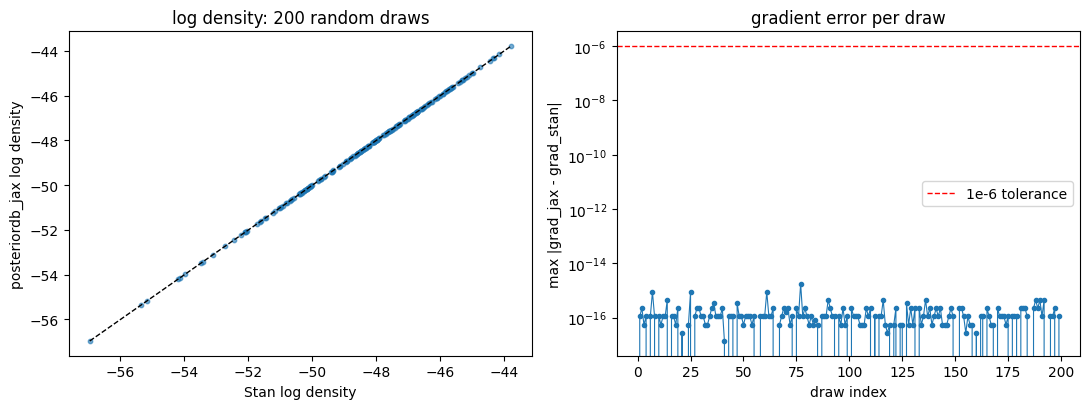

max log density abs err over 200 draws: 5.470262465223641e-09
max gradient abs err over 200 draws: 1.7763568394002505e-15


In [10]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 200
xs_np = rng.normal(size=(n, model.model_spec.free_dim))
xs = jnp.asarray(xs_np)

lp_jax_all = np.asarray(model.log_prob_unconstrained_batch(xs))
lp_stan_all = np.array([harness.log_density(x_i, propto=False, jacobian=True) for x_i in xs_np])

grad_err = []
for x_i in xs_np:
    _, g_stan = harness.log_density_gradient(x_i, propto=False, jacobian=True)
    g_jax = np.asarray(model.grad_unconstrained(jnp.asarray(x_i)))
    grad_err.append(np.max(np.abs(g_jax - g_stan)))
grad_err = np.array(grad_err)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(lp_stan_all, lp_jax_all, s=10, alpha=0.6)
lims = [min(lp_stan_all.min(), lp_jax_all.min()), max(lp_stan_all.max(), lp_jax_all.max())]
axes[0].plot(lims, lims, color="black", linewidth=1, linestyle="--")
axes[0].set_xlabel("Stan log density")
axes[0].set_ylabel("posteriordb_jax log density")
axes[0].set_title(f"log density: {n} random draws")

axes[1].semilogy(grad_err, marker="o", markersize=3, linewidth=0.8)
axes[1].axhline(1e-6, color="red", linestyle="--", linewidth=1, label="1e-6 tolerance")
axes[1].set_xlabel("draw index")
axes[1].set_ylabel("max |grad_jax - grad_stan|")
axes[1].set_title("gradient error per draw")
axes[1].legend()

fig.tight_layout()
plt.show()

print("max log density abs err over", n, "draws:", np.max(np.abs(lp_jax_all - lp_stan_all)))
print("max gradient abs err over", n, "draws:", grad_err.max())

## Summary

- `model.log_prob_unconstrained` / `grad_unconstrained` / `hessian_unconstrained`
  / `hvp_unconstrained` compute the log density and its derivatives in
  Stan's own sampling (unconstrained) space; `..._constrained` variants do
  the same directly in the natural parameterization.
- `model.grad_wrt_data` differentiates the log density with respect to the
  *data* itself (e.g. `y`, `sigma`) — something a compiled Stan model
  cannot do without recompiling.
- `StanComparisonHarness` + `assert_matches_stan` verify all of the above
  against a live, compiled Stan model through BridgeStan, and agree to
  within `1e-6` (log density, gradient, constrained parameters) here.

To try a different model, change `MODEL_NAME`/`DATA_NAME` above to any key
in `posteriordb_jax.models.MODEL_REGISTRY` (paired with the data file its
`posteriors/*.json` entry references) — see `README.md`'s model table for
the full list of 96 converted models.